# Risk Analysis Tutorials: Week 1 - Data Analysis 🔍 📊

Welcome to the Week 1 tutorial! 👋  

#### ✅ How to use this notebook

1. To save your own progress: Go to **File → Save a copy in Drive** (recommended)
2. Run the next cell once. In Google Colab it downloads the two week 1 data files into the working directory.  
3. You can run cells one by one using the play button on the top left of the cell or `Shift + Enter`.

**⚠️ Note: All work done here is temporary unless you save your own copy. Each time you reopen the notebook, Colab starts a new session.**

In [1]:
# Execute this cell once per session. Do not modify it.
import shutil
import sys
import urllib.request
from pathlib import Path

if "google.colab" in sys.modules:
    leftover = Path("/content/risk-analysis")
    if leftover.exists():
        shutil.rmtree(leftover)
    base = "https://raw.githubusercontent.com/theresa-hefele/risk-analysis/main/week1/data/"
    names = ("aircraft_losses.csv", "weather_fires.csv")
    for name in names:
        urllib.request.urlretrieve(base + name, name)
    print("Data files:", ", ".join(names))

# Working with Real Data 📊🔬

## Task 1 – ✈️ Aircraft Losses Analysis

In this task, we will explore a dataset of **commercial aircraft losses**  
with more than **100 fatalities per year**, covering the years **1960 to 2012**.

This corresponds to problem 2.1 in the lecture notes

### **Your first steps: Explore the data**

Before analyzing, it’s important to **understand the structure** of your dataset.

1. Load the dataset into a pandas DataFrame.
      ```python
      import pandas as pd
      aircraft_losses = pd.read_csv('aircraft_losses.csv')
      ```

2. Use the following methods to explore it:
   - `.info()` → see data types, missing values, and columns  
   - `.head()` → preview the first few rows  
   - `.describe()` → get summary statistics for numeric columns

💡 *Remark:*  
These methods are your first step in any data analysis workflow — they help you understand the dataset before doing calculations or plotting.


In [2]:
# Getting to know the data
import pandas as pd
from pathlib import Path

def week1_file(name):
    """Find a data file in Colab (working directory) or in this repository."""
    for candidate in (Path(name), Path("data") / name, Path("week1/data") / name):
        if candidate.exists():
            return candidate
    raise FileNotFoundError(name)

aircraft_losses = pd.read_csv(week1_file("aircraft_losses.csv"))
print(aircraft_losses.info())
print(aircraft_losses.head())
print(aircraft_losses.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Year    53 non-null     int64
 1   Events  53 non-null     int64
dtypes: int64(2)
memory usage: 976.0 bytes
None
   Year  Events
0  1960       1
1  1961       0
2  1962       4
3  1963       3
4  1964       0
              Year     Events
count    53.000000  53.000000
mean   1986.000000   3.622642
std      15.443445   2.194630
min    1960.000000   0.000000
25%    1973.000000   2.000000
50%    1986.000000   4.000000
75%    1999.000000   4.000000
max    2012.000000  11.000000


Based on the dataset of ✈️ commercial aircraft losses, calculate the following:

- **Sample mean** – the average number of losses per year  
- **Sample median** – the middle value in the dataset  
- **Sample standard deviation** – spread of the data  
- **Sample coefficient of variation** – the standard deviation relative to the mean  
- **Annual number of losses** of commercial aircraft with more than 100 fatalities for the period **2000–2012**

💡 *Hint:*  
Use pandas methods like `.mean()`, `.median()`, `.std()` and filtering by year to compute these statistics.


In [3]:
print(f"Events mean: {aircraft_losses['Events'].mean()}")

print(f"Events median: {aircraft_losses['Events'].median()}")

print(f"Event std: {aircraft_losses['Events'].std()}")

sample_coefficient_of_variation = aircraft_losses['Events'].std() / aircraft_losses['Events'].mean()
print(f"Event coefficient of variation: {sample_coefficient_of_variation}")

# Annual number of losses, 2000-2012
losses_2000_2012 = aircraft_losses[(aircraft_losses["Year"] >= 2000) & (aircraft_losses["Year"] <= 2012)]
print("\nAnnual losses, 2000-2012:")
print(losses_2000_2012)


Events mean: 3.6226415094339623
Events median: 4.0
Event std: 2.1946299415964243
Event coefficient of variation: 0.6058093067948462

Annual losses, 2000-2012:
    Year  Events
40  2000       4
41  2001       6
42  2002       6
43  2003       5
44  2004       1
45  2005       7
46  2006       4
47  2007       3
48  2008       1
49  2009       4
50  2010       3
51  2011       0
52  2012       2


### 🔥 Task 2 – Fire Data Analysis

In this task, you’ll work with real **weather and wildfire data** to explore how environmental factors influence the occurrence of fires. This corresponds to problem 2.4 of the lecture notes.

#### 🧾 **Dataset Columns**

| **Column** | **Description** | **Unit** |
|-------------|-----------------|-----------|
| `WS` | Wind Speed | km/h |
| `Temp` | Temperature | °C |
| `RH` | Relative Humidity | % |
| `Prec` | Precipitation | mm |
| `Fires` | Number of fire events per day | — |

#### 🌦️ **Weather Stations**

1. **Akrotiri** – Akrotiri RAF / 34° 35' N, 32° 59' E, 23 m a.s.l.
2. **Paphos** – Paphos Airport / 34° 43' N, 32° 29' E, 11 m a.s.l.
3. **Larnaka** – Larnaca Airport / 34° 52' N, 33° 37' E, 9 m a.s.l.


#### **(a) Explore the dataset**

Use `.info()`, `.head()`, and `.describe()` to get a feel for the data. Do not forget to load tht data :)


In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# a) explore the data
weather_fire_data = pd.read_csv(week1_file("weather_fires.csv"))
print(weather_fire_data.info())
print(weather_fire_data.head())
print(weather_fire_data.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           730 non-null    int64  
 1   Number         730 non-null    int64  
 2   Akrotiri_Prec  730 non-null    float64
 3   Larnaka_Prec   730 non-null    float64
 4   Paphos_Prec    730 non-null    float64
 5   Akrotiri_RH    730 non-null    float64
 6   Larnaka_RH     730 non-null    float64
 7   Paphos_RH      730 non-null    float64
 8   Akrotiri_Temp  730 non-null    float64
 9   Larnaka_Temp   730 non-null    float64
 10  Paphos_Temp    730 non-null    float64
 11  Akrotiri_WS    730 non-null    float64
 12  Larnaka_WS     730 non-null    float64
 13  Paphos_WS      730 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 80.0 KB
None
       Date  Number  Akrotiri_Prec  ...  Akrotiri_WS  Larnaka_WS  Paphos_WS
0  20060101       0            0.1  ...       27.880      

#### **(b) Time series for 2006**

Plot time series of:

- number of wildfires
- temperature
- relative humidity

for the year **2006**.


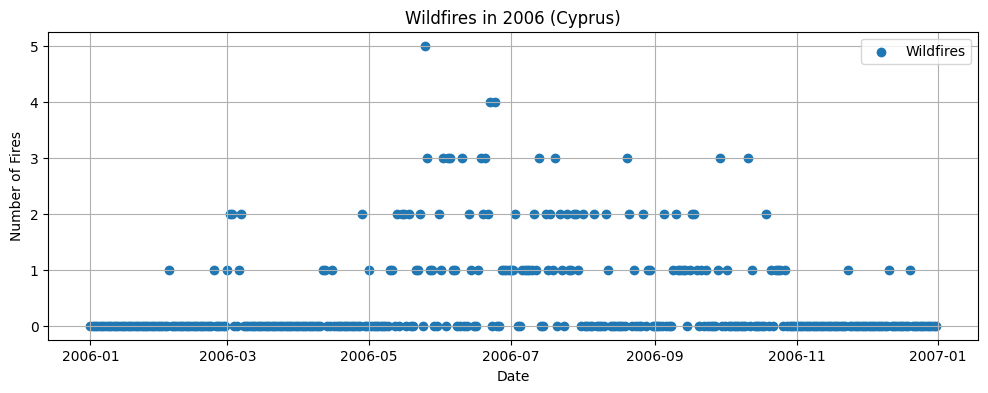

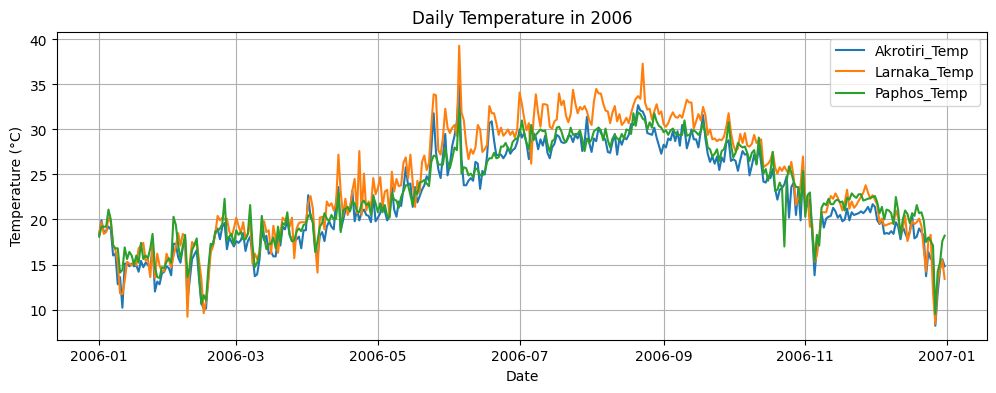

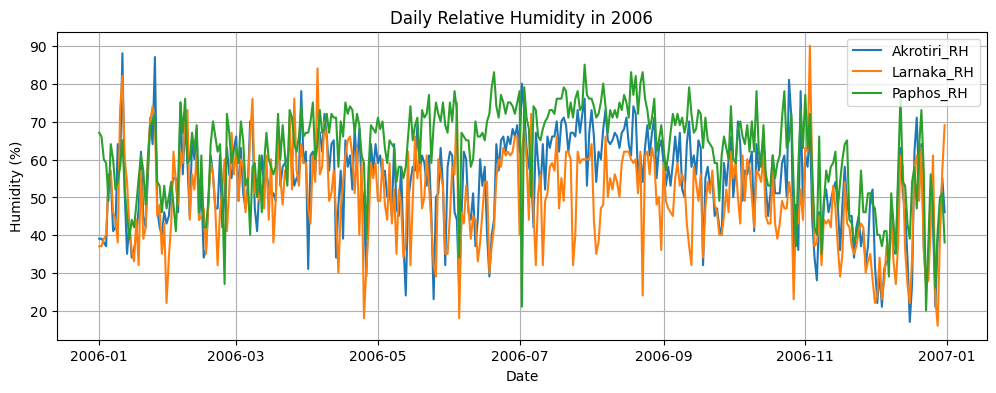

In [5]:
# b) plot time series diagrams

# Ensure Date is datetime
weather_fire_data["Date"] = pd.to_datetime(weather_fire_data["Date"], format="%Y%m%d")

# Filter for 2006
df_2006 = weather_fire_data[weather_fire_data["Date"].dt.year == 2006]

temp_cols = ["Akrotiri_Temp", "Larnaka_Temp", "Paphos_Temp"]
humidity_cols = ["Akrotiri_RH", "Larnaka_RH", "Paphos_RH"]

# ---- Plot Wildfires ----
plt.figure(figsize=(12, 4))
plt.scatter(df_2006["Date"], df_2006["Number"], label="Wildfires")
plt.title("Wildfires in 2006 (Cyprus)")
plt.xlabel("Date")
plt.ylabel("Number of Fires")
plt.legend()
plt.grid(True)
plt.show()

# ---- Plot Temperature ----
plt.figure(figsize=(12, 4))
for col in temp_cols:
    plt.plot(df_2006["Date"], df_2006[col], label=col)
plt.title("Daily Temperature in 2006")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()

# ---- Plot Humidity ----
plt.figure(figsize=(12, 4))
for col in humidity_cols:
    plt.plot(df_2006["Date"], df_2006[col], label=col)
plt.title("Daily Relative Humidity in 2006")
plt.xlabel("Date")
plt.ylabel("Humidity (%)")
plt.legend()
plt.grid(True)
plt.show()


#### **(c) Temperature on days with and without fires**

Plot **two normalized frequency diagrams** (histograms) of temperature:

- one for days **with fires**
- one for days **without fires**

💡 *Hint:* `df[df['Fires'] > 0]` selects days with fires.

In the cell below the plot, answer: *How does temperature affect the probability of wildfires?*


Mean temperature on fire days: 27.7 °C
Mean temperature on days without fires: 22.2 °C
Share of days above 30 °C that have a fire: 0.54
Higher temperature goes together with a higher chance of wildfires. Fire days are warmer on average, and more than half of the days above 30 °C have at least one fire.


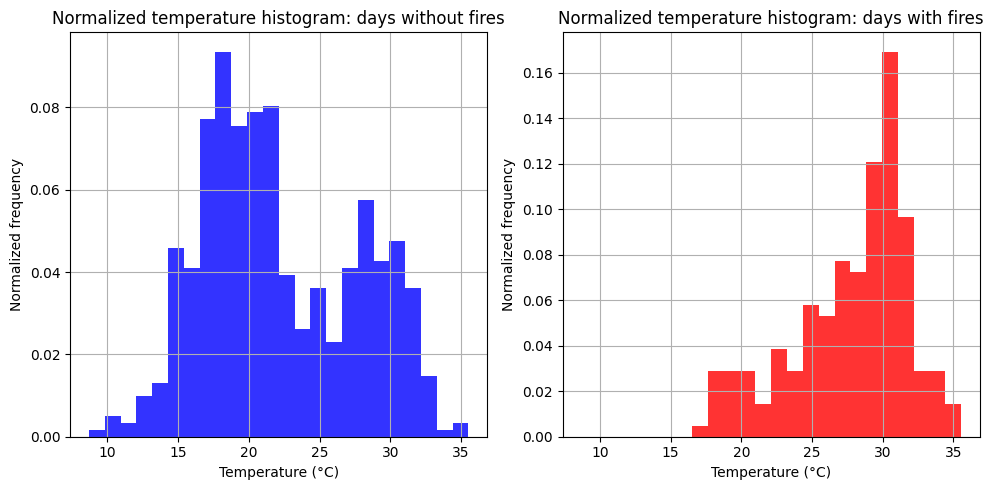

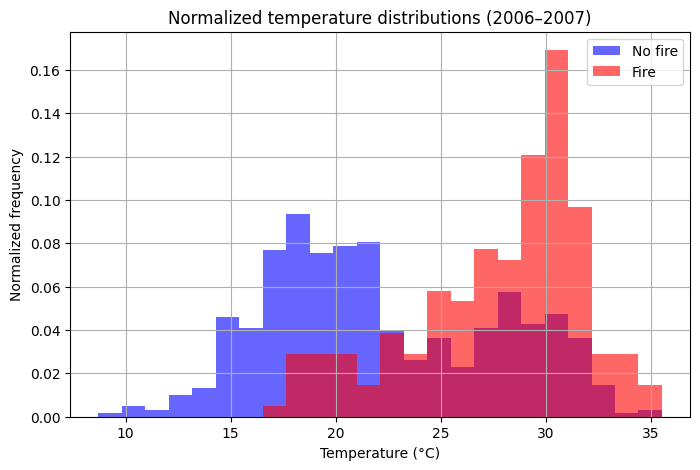

In [6]:
# c) plot normalized frequency diagrams of temperature
import numpy as np

temp_cols = ["Akrotiri_Temp", "Larnaka_Temp", "Paphos_Temp"]

# Average daily temperature across the 3 stations
weather_fire_data["Mean_Temp"] = weather_fire_data[temp_cols].mean(axis=1)

# Separate fire vs no-fire days
weather_fire_data["FireDay"] = weather_fire_data["Number"] > 0
temps_fire = weather_fire_data.loc[weather_fire_data["FireDay"], "Mean_Temp"]
temps_no_fire = weather_fire_data.loc[~weather_fire_data["FireDay"], "Mean_Temp"]

bins = np.linspace(weather_fire_data["Mean_Temp"].min(), weather_fire_data["Mean_Temp"].max(), 25)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(temps_no_fire, bins=bins, color="blue", alpha=0.8, density=True)
plt.title("Normalized temperature histogram: days without fires")
plt.xlabel("Temperature (°C)")
plt.ylabel("Normalized frequency")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.hist(temps_fire, bins=bins, color="red", alpha=0.8, density=True)
plt.title("Normalized temperature histogram: days with fires")
plt.xlabel("Temperature (°C)")
plt.ylabel("Normalized frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

# Same comparison on one set of axes
plt.figure(figsize=(8, 5))
plt.hist(temps_no_fire, bins=bins, color="blue", density=True, alpha=0.6, label="No fire")
plt.hist(temps_fire, bins=bins, color="red", density=True, alpha=0.6, label="Fire")
plt.title("Normalized temperature distributions (2006–2007)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Normalized frequency")
plt.legend()
plt.grid(True)
plt.show()

print(f"Mean temperature on fire days: {temps_fire.mean():.1f} °C")
print(f"Mean temperature on days without fires: {temps_no_fire.mean():.1f} °C")

hot = weather_fire_data["Mean_Temp"] > 30
share_hot_with_fire = weather_fire_data.loc[hot, "FireDay"].mean()
print(f"Share of days above 30 °C that have a fire: {share_hot_with_fire:.2f}")
print(
    "Higher temperature goes together with a higher chance of wildfires. "
    "Fire days are warmer on average, and more than half of the days above 30 °C have at least one fire."
)


#### **(d) Humidity and temperature**

Determine the **correlation** between relative humidity and temperature, and visualize it with a scatter plot.

💡 *Hint:* `.corr()` computes the correlation. `.plot(kind='scatter')` or `plt.scatter()` draws the scatter plot.


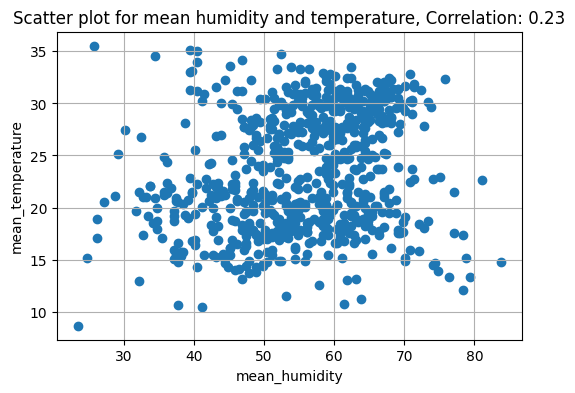

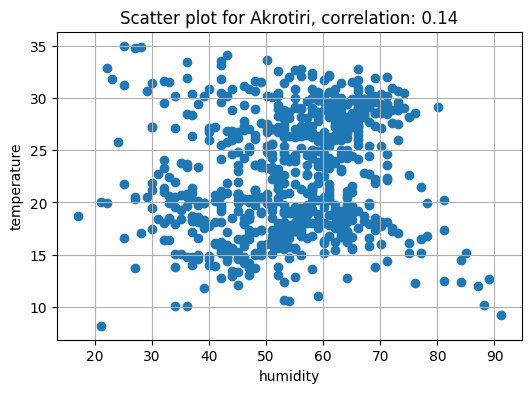

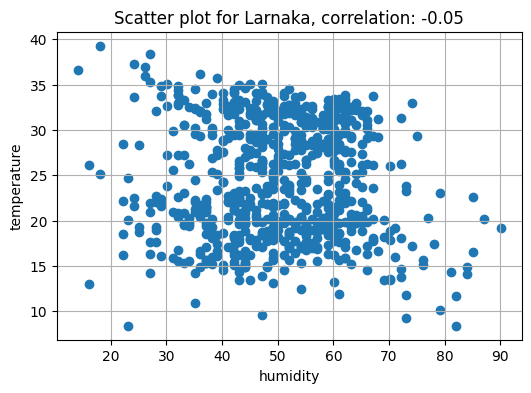

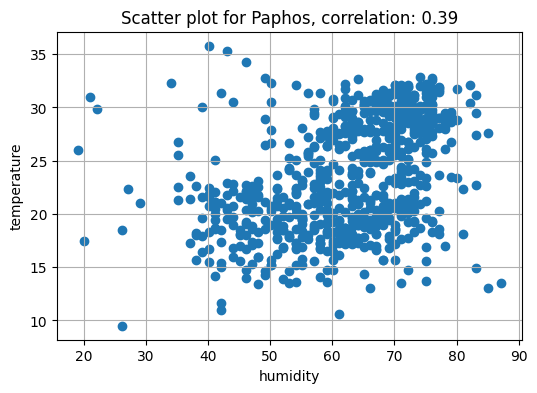

In [7]:
# d) determine the correlation between relative humidity and temperature & plot a scatter plot

# Identify temperature and humidity columns
temp_cols = ["Akrotiri_Temp", "Larnaka_Temp", "Paphos_Temp"]
humidity_cols = ["Akrotiri_RH", "Larnaka_RH", "Paphos_RH"]
stations = ["Akrotiri", "Larnaka", "Paphos"]

mean_temperature = weather_fire_data[temp_cols].mean(axis=1)
mean_humidity = weather_fire_data[humidity_cols].mean(axis=1)

# Calculate correlation between mean temperature and mean humidity
corr_mean_temp_humidity = mean_temperature.corr(mean_humidity)

plt.figure(figsize=(6, 4))
plt.scatter(mean_humidity, mean_temperature)
plt.ylabel("mean_temperature")
plt.xlabel("mean_humidity")
plt.title(f"Scatter plot for mean humidity and temperature, Correlation: {corr_mean_temp_humidity:.2f}")
plt.grid(True)
plt.show()

for i, station in enumerate(stations):
    humidity = weather_fire_data[humidity_cols[i]]
    temperature = weather_fire_data[temp_cols[i]]

    plt.figure(figsize=(6, 4))
    plt.scatter(humidity, temperature)
    plt.ylabel("temperature")
    plt.xlabel("humidity")
    plt.title(f"Scatter plot for {station}, correlation: {temperature.corr(humidity):.2f}")
    plt.grid(True)
    plt.show()
